# Predictive Modeling Using Machine Learning
**Goal:** Predict whether a breast tumor is **malignant** or **benign** using supervised learning.

**Models:** Logistic Regression, Decision Tree, Random Forest
**Evaluation:** Accuracy, Precision, Recall, F1, Confusion Matrix, ROC Curve, Cross-Validation

**Dataset:** Breast Cancer Wisconsin (built into scikit-learn, 569 samples, 30 features)

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report)

sns.set_style('whitegrid')
RANDOM_STATE = 42

## 2. Load the data
The `target` column is what we predict: **0 = malignant, 1 = benign**.

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame
print('Shape:', df.shape)
df.head()

Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 3. Explore the data (EDA)

In [3]:
print('Missing values:', df.isnull().sum().sum())
print(df['target'].value_counts().rename({0: 'Malignant', 1: 'Benign'}))
df.describe().T.head(10)

Missing values: 0
target
Benign       357
Malignant    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


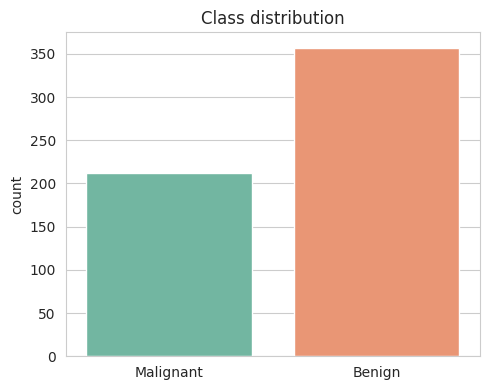

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df['target'].map({0: 'Malignant', 1: 'Benign'}), ax=ax, palette='Set2')
ax.set_title('Class distribution'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

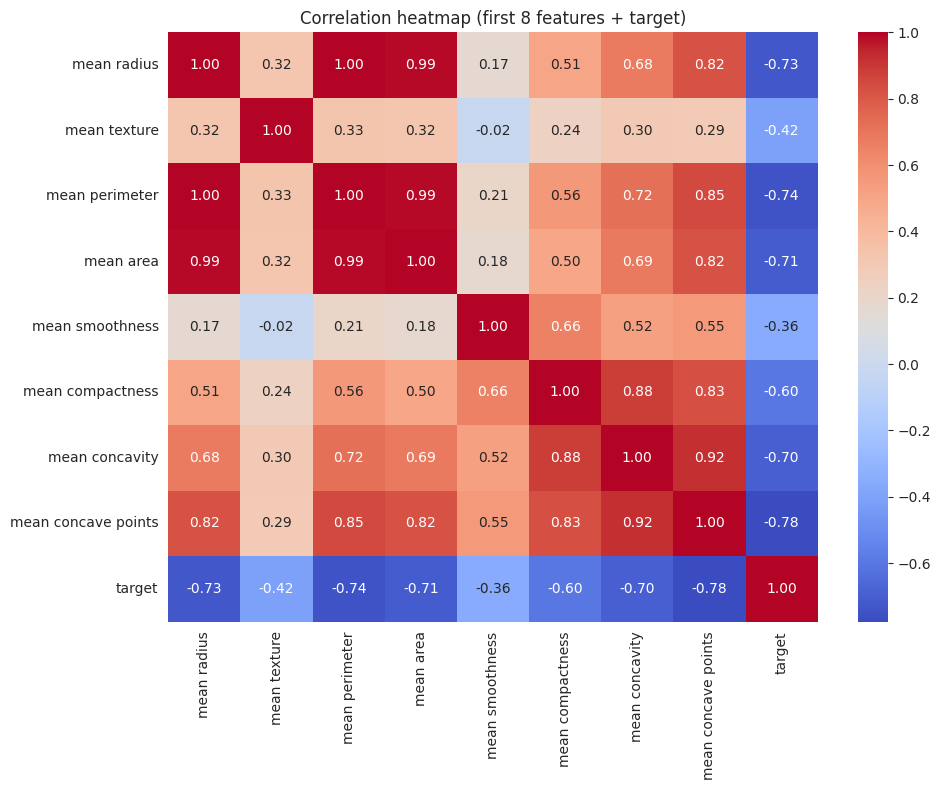

In [5]:
plt.figure(figsize=(10, 8))
cols = list(df.columns[:8]) + ['target']
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap (first 8 features + target)')
plt.tight_layout(); plt.show()

**Observations:** There are no missing values. Classes are moderately imbalanced (about 63% benign / 37% malignant), so we use a *stratified* split. Size-related features (radius, perimeter, area) are strongly correlated with each other.

## 4. Train / test split
The model learns from 80% of the data and is graded on the unseen 20%.

In [6]:
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (455, 30)  Test: (114, 30)


## 5. Build and train models
Linear Regression predicts numbers, so for a yes/no outcome we use its classification counterpart, **Logistic Regression**. Scaling is wrapped in a `Pipeline` so the scaler is fitted on training data only (prevents data leakage).

In [7]:
models = {
    'Logistic Regression': Pipeline([('scaler', StandardScaler()),
                                     ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print('Trained:', name)

Trained: Logistic Regression
Trained: Decision Tree


Trained: Random Forest


## 6. Evaluate on the test set

In [8]:
rows, preds = [], {}
for name, m in models.items():
    p = m.predict(X_test); preds[name] = p
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, p),
                 'Precision': precision_score(y_test, p),
                 'Recall': recall_score(y_test, p),
                 'F1': f1_score(y_test, p),
                 'ROC AUC': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
results = pd.DataFrame(rows).set_index('Model').round(3)
results

,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Logistic Regression,0.982,0.986,0.986,0.986,0.995
Decision Tree,0.939,0.958,0.944,0.951,0.934
Random Forest,0.956,0.959,0.972,0.966,0.993


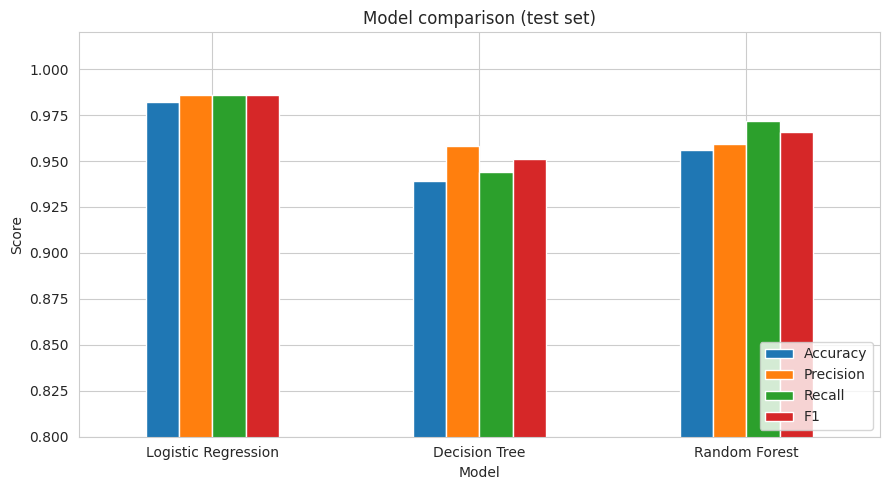

In [9]:
results[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(9, 5), rot=0, ylim=(0.8, 1.02))
plt.title('Model comparison (test set)'); plt.ylabel('Score'); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

In [10]:
for name, p in preds.items():
    print('=' * 50); print(name); print(classification_report(y_test, p, target_names=['Malignant', 'Benign']))

Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Decision Tree
              precision    recall  f1-score   support

   Malignant       0.91      0.93      0.92        42
      Benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114

Random Forest
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96   

## 7. Confusion matrices
Diagonal = correct predictions. Off-diagonal = mistakes. A *benign* prediction for a truly *malignant* tumor (bottom-left box of the top row) is the most dangerous error.

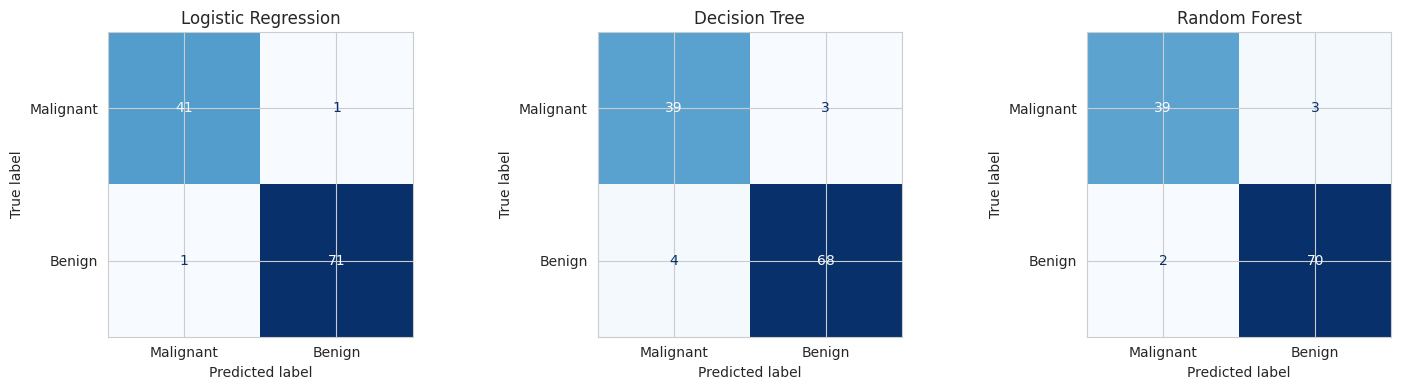

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=['Malignant', 'Benign'], ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 8. ROC curves
The closer a curve is to the top-left corner (AUC near 1), the better.

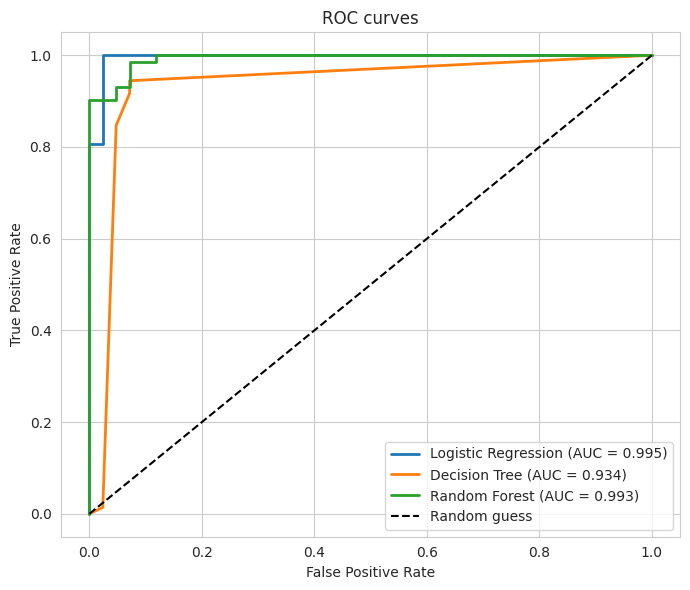

In [12]:
plt.figure(figsize=(7, 6))
for name, m in models.items():
    prob = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('ROC curves')
plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 9. Cross-validation
A single split can be lucky or unlucky. 5-fold cross-validation gives a more reliable estimate.

In [13]:
cv_rows = []
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=5, scoring='accuracy')
    cv_rows.append({'Model': name, 'Mean accuracy': s.mean(), 'Std': s.std()})
pd.DataFrame(cv_rows).set_index('Model').round(3)

,Mean accuracy,Std
Model,,
Logistic Regression,0.981,0.007
Decision Tree,0.921,0.020
Random Forest,0.958,0.024


## 10. Feature importance (Random Forest)

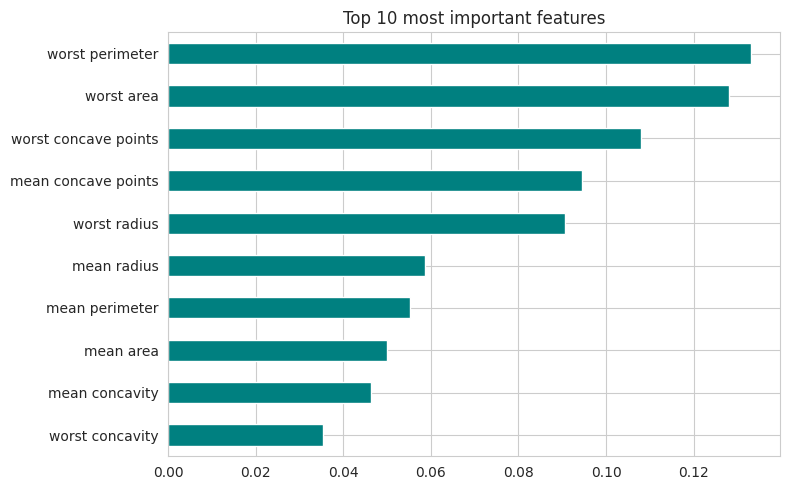

In [14]:
imp = pd.Series(models['Random Forest'].feature_importances_, index=X.columns).sort_values(ascending=False)[:10]
imp.sort_values().plot(kind='barh', figsize=(8, 5), color='teal')
plt.title('Top 10 most important features'); plt.tight_layout(); plt.show()

## 11. Visualize the Decision Tree

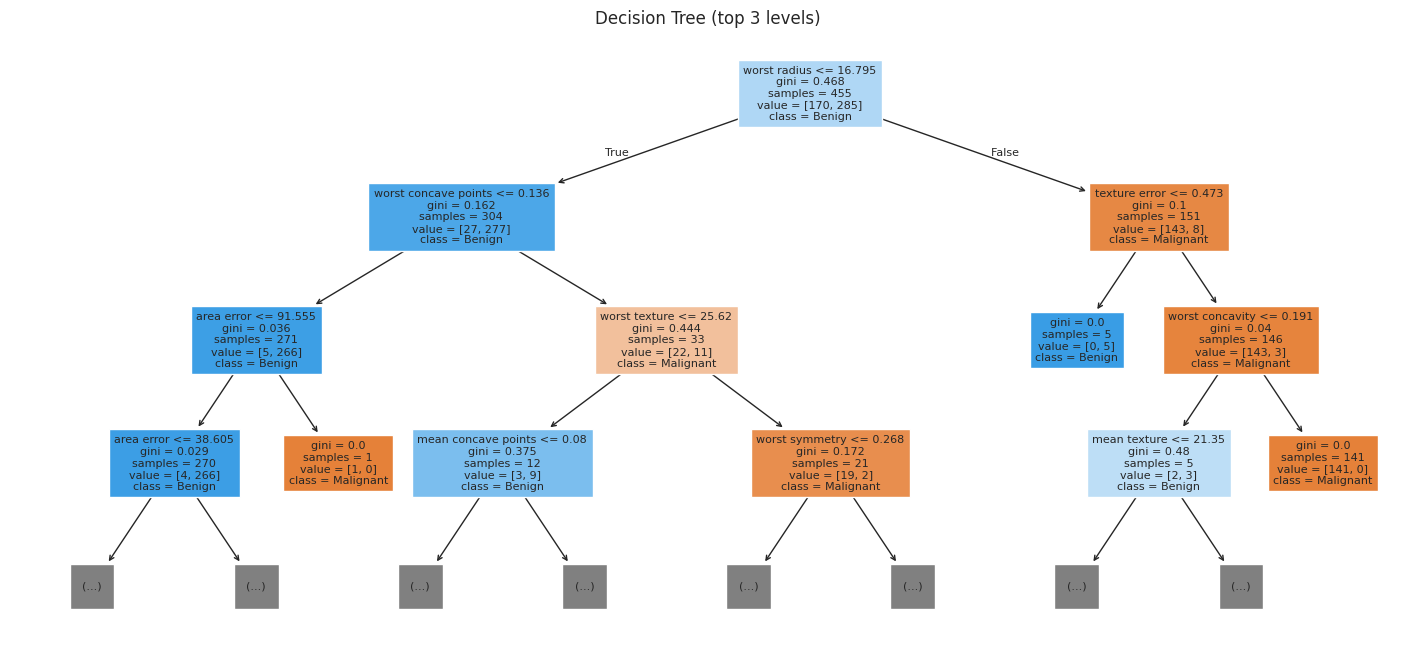

In [15]:
plt.figure(figsize=(18, 8))
plot_tree(models['Decision Tree'], feature_names=X.columns, class_names=['Malignant', 'Benign'], filled=True, max_depth=3, fontsize=8)
plt.title('Decision Tree (top 3 levels)'); plt.show()

## 12. Hyperparameter tuning (bonus)

In [16]:
grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                    {'n_estimators': [100, 200], 'max_depth': [None, 5, 10], 'min_samples_split': [2, 5]},
                    cv=5, scoring='recall', n_jobs=-1)
grid.fit(X_train, y_train)
print('Best params:', grid.best_params_)
print('Test accuracy:', round(accuracy_score(y_test, grid.predict(X_test)), 3))
print('Test recall  :', round(recall_score(y_test, grid.predict(X_test)), 3))

Best params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Test accuracy: 0.956
Test recall  : 0.972


## 13. Conclusion
- **Best model:** Compare the results table above. Logistic Regression and Random Forest typically score highest (about 96-98% accuracy, AUC near 0.99), while the single Decision Tree is a little behind but is the most interpretable.
- **Metric choice:** In medical screening, missing a malignant tumor is the costliest error, so recall for the malignant class matters a lot, not just accuracy.
- **Key features:** Worst-case measurements such as worst perimeter, worst radius, and worst concave points drive Random Forest predictions.
- **Next steps:** Try other algorithms (SVM, Gradient Boosting), tune the decision threshold to favor recall, and validate on an external dataset.
- **Caveat:** This is a learning project, not a clinical tool.